# **Netflix Business Insights Report**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("Cleaned_Dataset.csv")

**Dataset Overview**

In [ ]:
data.head()

,Show_Id,Type,Title,Director,Country,Date_Added,Release_Year,Rating,Duration,Listed_In
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [ ]:
print("Shape of Data: ", data.shape)
print("\nColumns: " )
data.columns

Shape of Data:  (8790, 10)

Columns: 


Index(['Show_Id', 'Type', 'Title', 'Director', 'Country', 'Date_Added',
       'Release_Year', 'Rating', 'Duration', 'Listed_In'],
      dtype='object')

In [ ]:
data.info()
print("\nStatistical Details of Data")
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Show_Id       8790 non-null   object
 1   Type          8790 non-null   object
 2   Title         8790 non-null   object
 3   Director      8790 non-null   object
 4   Country       8790 non-null   object
 5   Date_Added    8790 non-null   object
 6   Release_Year  8790 non-null   int64 
 7   Rating        8790 non-null   object
 8   Duration      8790 non-null   object
 9   Listed_In     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB

Statistical Details of Data


,Release_Year
count,8790.000000
mean,2014.183163
std,8.825466
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


**Data Quality Assessment**

In [ ]:
print("No of Missing Values: ",data.isnull().sum())
print("No of Duplicated Values: ",data.duplicated().sum())

No of Missing Values:  Show_Id         0
Type            0
Title           0
Director        0
Country         0
Date_Added      0
Release_Year    0
Rating          0
Duration        0
Listed_In       0
dtype: int64
No of Duplicated Values:  0


### **Exploratory Data Analysis**

**Movies vs TV Shows**

In [ ]:
content_counts = data["Type"].value_counts()
print(content_counts)

Type
Movie      6126
TV Show    2664
Name: count, dtype: int64


**Dashboard 1 — Content Overview**

In [ ]:
total_titles = len(data)
movies_count = (data["Type"] == "Movie").sum()
tv_count = (data["Type"] == "TV Show").sum()

print("Total Titles:", total_titles)
print("Movies:", movies_count)
print("TV Shows:", tv_count)

Total Titles: 8790
Movies: 6126
TV Shows: 2664


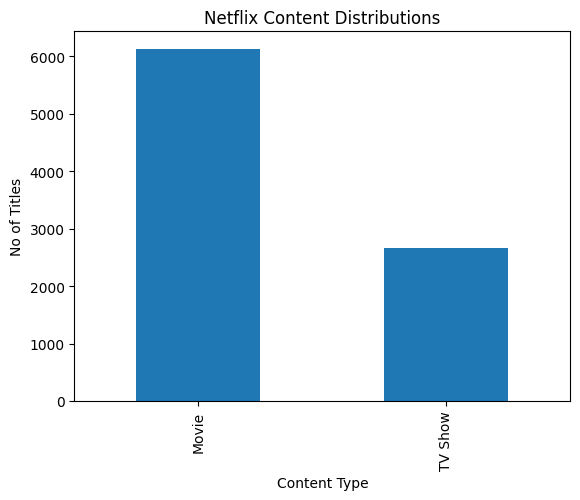

In [ ]:
##Visualization of Distributions
content_counts.plot(kind = "bar")

plt.title("Netflix Content Distributions")
plt.xlabel("Content Type")
plt.ylabel("No of Titles")
plt.show()

**Business Insight:** The Netflix catalog contains both Movies and TV Shows, with Movies representing a larger share of the available titles. This indicates that Netflix's content library has a strong movie oriented component , while TV Shows provide an important complementary form of long form content .

**Release Year Analysis**

In [ ]:
print("Content Distribution by Release Year\n")
yearly_content = data["Release_Year"].value_counts().sort_index()

print(yearly_content)

Content Distribution by Release Year

Release_Year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64


**Dashboard 2 —  Annual Content Growth**

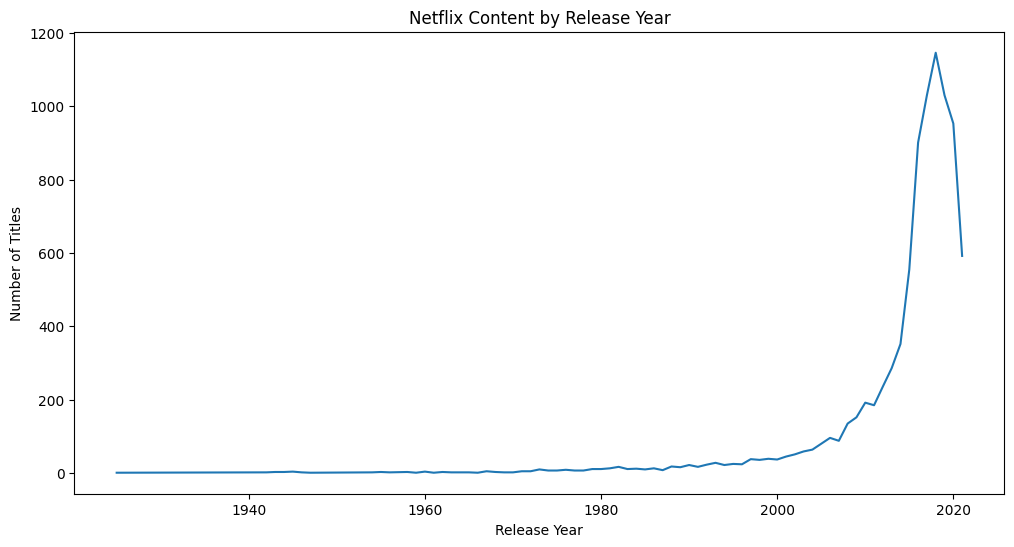

In [ ]:
##Visualization of Growth
##Line plot (best for showing growth/trends)
plt.figure(figsize=(12, 6))
plt.plot( yearly_content.index, yearly_content.values)

plt.title("Netflix Content by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.show()

**Business Insight:** The distribution of titles across release years shows how the Netflix catalog represents content from different periods. The concentration of titles in more recent years indicates substantial representation of newer content, while older titles contribute additional catalog depth and variety

**Country Analysis**

In [ ]:
print("Content Generated by each Country\n")
country_content_count = data["Country"].value_counts()
print(country_content_count)

Content Generated by each Country

Country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
                  ... 
Luxembourg           1
Senegal              1
Belarus              1
Puerto Rico          1
Cyprus               1
Name: count, Length: 86, dtype: int64


**Dashboard 3 — Geographic Insights**

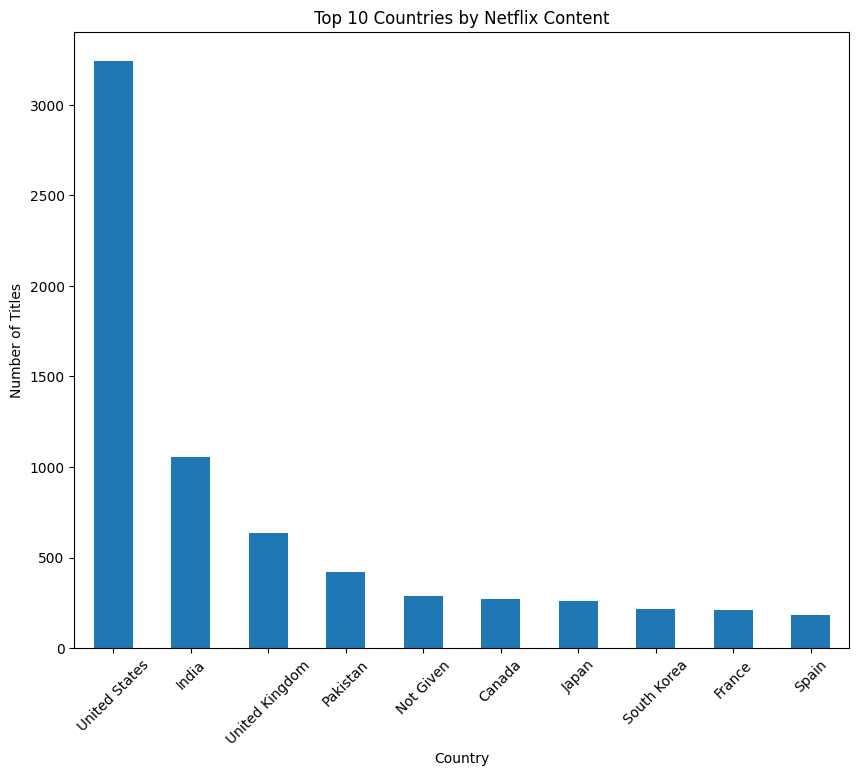

In [ ]:
##Visualization of Countries' Content
top_countries = country_content_count.head(10)
top_countries.plot(kind="bar",figsize=(10, 8))

plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

**Business Insight:** The country analysis shows that Netflix content is distributed across a wide range of countries, although some countries have substantially greater representation than others. This demonstrates both strong representation from major content producing markets and geographic diversity within the catalog.

The Top 10 country analysis identifies the markets contributing the largest number of titles to the Netflix catalog. Comparing these markets helps highlight where Netflix has particularly strong content representation and provides an overview of the geographic concentration of its library.

**Genre Analysis**

In [ ]:
genre_counts = data["Listed_In"].value_counts()
genre_counts.head(10)

,count
Listed_In,
"Dramas, International Movies",362
Documentaries,359
Stand-Up Comedy,334
"Comedies, Dramas, International Movies",274
"Dramas, Independent Movies, International Movies",252
Kids' TV,219
Children & Family Movies,215
"Children & Family Movies, Comedies",201
"Documentaries, International Movies",186


**Dashboard 4 — Content Trends (Genre Distributions & Ratings)**

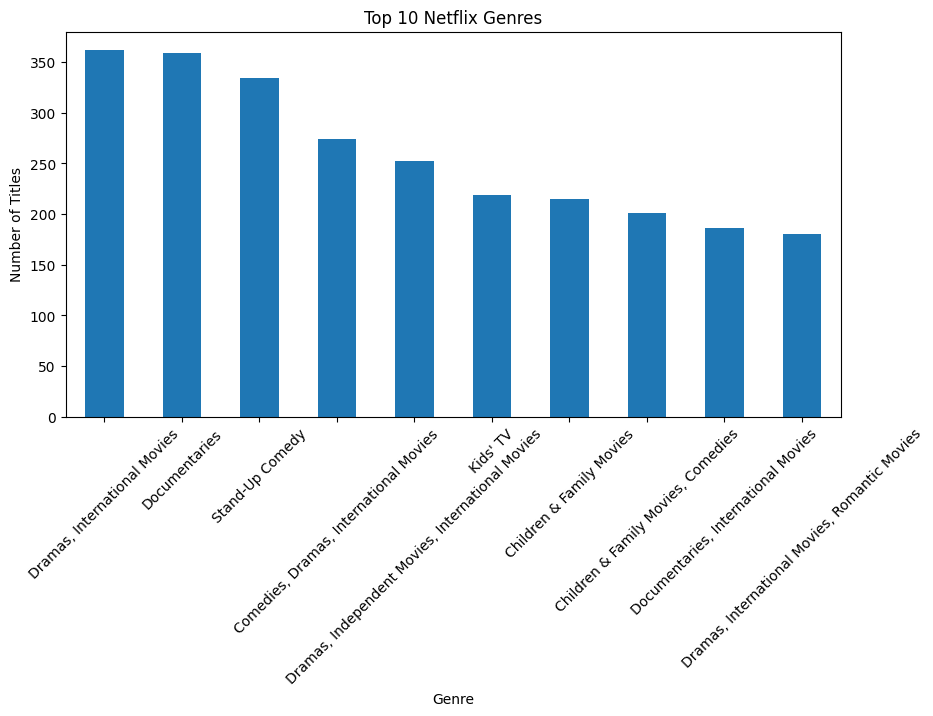

In [ ]:
##Visualization of Genre Counts
genre_counts.head(10).plot(kind="bar",figsize=(10, 5),title="Top 10 Netflix Genres")

plt.xlabel("Genre")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

**Business Insight:** The genre analysis identifies the content categories that occur most frequently in the Netflix catalog. A diverse range of genres indicates that the catalog serves different audience interests, while highly represented genres may indicate areas of particularly strong content availability.

**Rating Analysis**

In [ ]:
rating_counts = data["Rating"].value_counts()
print(rating_counts)

Rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


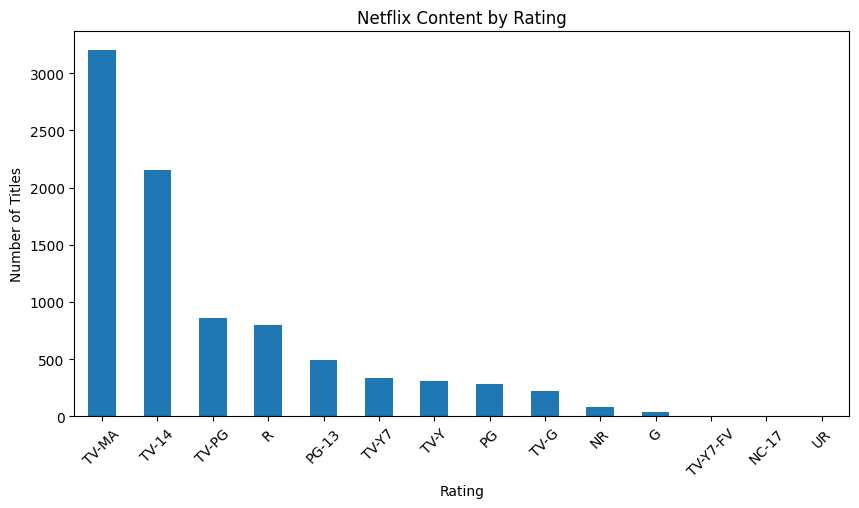

In [ ]:
##Visualization of Rating counts
rating_counts.plot(kind="bar",figsize=(10, 5),title="Netflix Content by Rating")

plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

**Business Insight:** The rating distribution shows the different audience categories represented within Netflix's catalog. The presence of multiple rating categories indicates that the library contains content intended for different age groups and audience segments.

**Movie Duration Analysis**

In [ ]:
movies = data[data["Type"] == "Movie"].copy()

##Extract only Numerical Part from Duration
movies["Duration_Minutes"] = (
    movies["Duration"]
    .str.extract(r"(\d+)")
    .astype(float)
)
movies["Duration_Minutes"]

,Duration_Minutes
0,90.0
3,91.0
4,125.0
6,104.0
7,87.0
...,...
8702,103.0
8707,75.0
8716,136.0
8763,89.0


In [ ]:
print(movies["Duration_Minutes"].describe())

count    6126.000000
mean       99.584884
std        28.283225
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: Duration_Minutes, dtype: float64


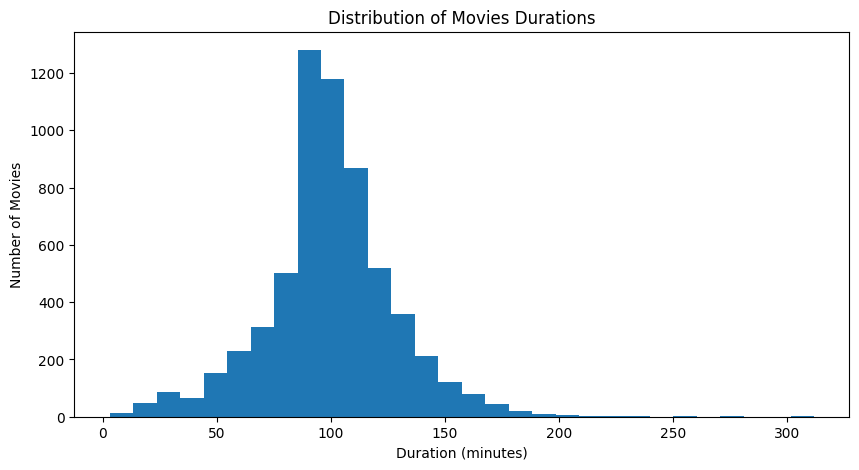

In [ ]:
##Visualization
##Histogram (For different ranges of Duration)
plt.figure(figsize=(10, 5))
plt.hist(movies["Duration_Minutes"].dropna(),bins=30)

plt.title("Distribution of Movies Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")

plt.show()

**Business Insight:** The movie duration analysis shows how movie lengths are distributed across different time ranges. Identifying the most common duration range helps characterize the typical length of movies available in the catalog and highlights whether the library is concentrated around shorter, medium length, or longer movies.

**TV Shows Season Analysis**

In [ ]:
tv_shows = data[data["Type"] == "TV Show"].copy()
tv_shows["Seasons"] = (
    tv_shows["Duration"]
    .str.extract(r"(\d+)")
    .astype(float)
)
tv_shows["Seasons"]

,Seasons
1,1.0
2,1.0
5,9.0
17,1.0
18,1.0
...,...
8785,2.0
8786,3.0
8787,1.0
8788,1.0


In [ ]:
print(tv_shows["Seasons"].describe())

count    2664.000000
mean        1.751877
std         1.550622
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: Seasons, dtype: float64


**Business Insight:** The TV Show season analysis provides an overview of the length of serialized content in the catalog. Comparing the number of seasons helps identify whether the TV Show library is primarily composed of shorter series or longer-running programs.

**KPI Summary**

In [ ]:
print("Total Titles:", len(data) ,"\n")

print( "Movies:", movies_count , "\n")

print("TV Shows:", tv_count , "\n")

print("Movies vs TV Shows Ratio on Netflix")
movie_percentage = movies_count / total_titles * 100
tv_percentage = tv_count / total_titles * 100

print(f"Movies: {movie_percentage:.2f}%")
print(f"TV Shows: {tv_percentage:.2f}%", "\n")

print("Top Country Generating Content:", top_countries.idxmax() , "\n")

print("Top Genre:",genre_counts.idxmax() , "\n")

print("Latest Release Year:",data["Release_Year"].max())

Total Titles: 8790 

Movies: 6126 

TV Shows: 2664 

Movies vs TV Shows Ratio on Netflix
Movies: 69.69%
TV Shows: 30.31% 

Top Country Generating Content: United States 

Top Genre: Dramas, International Movies 

Latest Release Year: 2021


**Business insights**

# **Key Business Insights**

### **1. Content Mix**

The dataset contains **8,790 titles**, including **6,126 Movies (69.7%)** and **2,664 TV Shows (30.3%)**. This shows that Movies make up the larger share of the Netflix catalog analyzed, accounting for nearly two-thirds of all titles.

### **2. Content Recency**

The release-year analysis shows that Netflix’s catalog includes content from a wide range of years. A significant portion of the titles comes from **more recent release years**, while older titles also contribute to the overall variety of the catalog.

### **3. Geographic Diversity**

Netflix’s catalog includes content associated with **many different countries**, showing a broad international presence. However, the number of titles varies considerably from country to country. In the analyzed dataset, the **United States has the highest number of associated titles**.

### **4. Genre Diversity**

The catalog includes a **wide variety of genres and content categories** covering both Movies and TV Shows. Some categories appear much more frequently than others, showing that while the catalog is diverse, certain types of content have stronger representation.

### **5. Audience Coverage**

The rating analysis shows that Netflix offers content for **different age groups and audience categories**. The variety of ratings indicates that the catalog caters to more than one type of viewer and includes content suitable for different audiences.

### **6. Movie Length**

The movie-duration analysis shows that movies in the catalog vary considerably in length. Most movies fall within a **typical duration range**, while shorter and longer movies make up smaller portions of the dataset. This gives an overall picture of the different viewing formats available in Netflix’s movie collection.

### **7. TV Content Structure**

The TV show analysis shows that the number of seasons varies across titles. Many shows have **relatively few seasons**, while a smaller number continue for several seasons. This highlights the different structures and lengths of TV content available in the Netflix catalog.


### **Overall Business Insight**

Overall, the analysis indicates that Netflix's catalog is characterized by a **large movie component, broad geographic and genre diversity, multiple audience rating categories, and varied movie and TV show structures**. At the same time, the distribution of titles is not uniform across countries, genres, ratings, release periods, or content formats, highlighting differences in how content is represented within the analyzed catalog.

#**Executive Summary**

The analysis looked at the Netflix content dataset in order to find out about its general makeup, content trends, representation by geographic region, genres, ratings, the lengths of movies, and the way TV show seasons are structured. The dataset includes 8,790 titles, of which 6,126 are Movies and 2,664 are TV Shows, movies making up the greater part of the catalog being analysed.

The analysis also revealed a good deal of geographic representation among the different countries, together with a wide range of content categories and audience ratings; when looking at the release years it was found that the catalogue includes titles from various periods, and further insight into the structure of the content library was given by the analysis of movie duration and TV show seasons.

The analysis as a whole shows how exploratory data analysis, visualization, key performance indicators, and business insights can be combined in order to gain an understanding of a large content catalog; the findings give a data-driven overview of Netflix's content portfolio and can thus form the basis for further analysis of content trends, audience segments, and geographic patterns.